# **Libraries**

In [149]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split , GridSearchCV
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import warnings
warnings.filterwarnings("ignore")

# **DataSet**

In [150]:
df = pd.read_excel("/content/Student performance balanced missior.xlsm", engine="openpyxl")

In [151]:
df.head()

,Gender,Parental Education Level,Lunch Type,Test Preparation Course,Study Time,Absences,Math Score,Reading Score,Writing Score
0,Male,Bachelor,Standard,NaN,12.7,6,74.2,68.7,67.7
1,Female,College,Standard,NaN,8.1,1,78.0,72.5,62.4
2,Male,College,Standard,NaN,10.8,5,67.0,72.0,72.9
3,Male,Bachelor,Standard,NaN,12.5,3,71.2,76.8,79.8
4,Male,Bachelor,Standard,Completed,9.9,4,82.9,75.9,75.7


In [152]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Gender                    1000 non-null   object 
 1   Parental Education Level  1000 non-null   object 
 2   Lunch Type                1000 non-null   object 
 3   Test Preparation Course   486 non-null    object 
 4   Study Time                1000 non-null   float64
 5   Absences                  1000 non-null   int64  
 6   Math Score                1000 non-null   float64
 7   Reading Score             1000 non-null   float64
 8   Writing Score             1000 non-null   float64
dtypes: float64(4), int64(1), object(4)
memory usage: 70.4+ KB


#**Cleaning**

In [153]:
df.isna().sum()

,0
Gender,0
Parental Education Level,0
Lunch Type,0
Test Preparation Course,514
Study Time,0
Absences,0
Math Score,0
Reading Score,0
Writing Score,0


In [154]:
df.loc[df['Test Preparation Course'].notna()]

,Gender,Parental Education Level,Lunch Type,Test Preparation Course,Study Time,Absences,Math Score,Reading Score,Writing Score
4,Male,Bachelor,Standard,Completed,9.9,4,82.9,75.9,75.7
5,Female,High School,Standard,Completed,11.4,6,64.1,63.4,54.2
7,Male,Bachelor,Standard,Completed,9.4,4,77.0,66.6,81.3
10,Male,Bachelor,Free/Reduced,Completed,9.5,8,66.2,66.3,68.4
12,Male,Master,Free/Reduced,Completed,8.5,6,71.9,70.5,74.9
...,...,...,...,...,...,...,...,...,...
988,Female,College,Standard,Completed,8.2,6,62.2,61.4,62.4
989,Female,College,Standard,Completed,11.0,6,74.9,67.3,64.6
990,Female,High School,Standard,Completed,13.8,5,74.2,68.3,69.1
995,Male,Bachelor,Standard,Completed,16.1,4,89.1,79.1,84.3


In [155]:
df.loc[df['Test Preparation Course'].notna(),'Study Time'].agg(['min', 'max', 'mean'])

,Study Time
min,1.000000
max,20.000000
mean,9.919136


In [156]:
df['Test Preparation Course'].unique()

array([nan, 'Completed'], dtype=object)

In [157]:
df['Test Preparation Course'] = df['Test Preparation Course'].fillna('Uncompleted')

In [158]:
df.duplicated().sum()

np.int64(0)

In [159]:
df["Exam Score"] = df[["Math Score", "Reading Score", "Writing Score"]].sum(axis=1).round(1)

In [160]:
df[["Math Score", "Reading Score", "Writing Score", "Exam Score"]].max()

,0
Math Score,100.0
Reading Score,100.0
Writing Score,100.0
Exam Score,287.0


In [161]:
df[["Math Score", "Reading Score", "Writing Score", "Exam Score"]].head()

,Math Score,Reading Score,Writing Score,Exam Score
0,74.2,68.7,67.7,210.6
1,78.0,72.5,62.4,212.9
2,67.0,72.0,72.9,211.9
3,71.2,76.8,79.8,227.8
4,82.9,75.9,75.7,234.5


In [162]:
df.describe()

,Study Time,Absences,Math Score,Reading Score,Writing Score,Exam Score
count,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,9.97700,4.921000,71.310100,68.393100,66.653400,206.356600
std,3.08813,2.086891,10.269462,9.660793,10.218016,27.292096
min,1.00000,0.000000,42.800000,36.100000,30.800000,116.500000
25%,7.90000,3.000000,64.100000,61.900000,60.000000,188.100000
50%,9.90000,5.000000,71.600000,68.500000,66.650000,206.600000
75%,12.02500,6.000000,78.425000,74.925000,73.800000,225.625000
max,20.00000,14.000000,100.000000,100.000000,100.000000,287.000000


#**EDA**

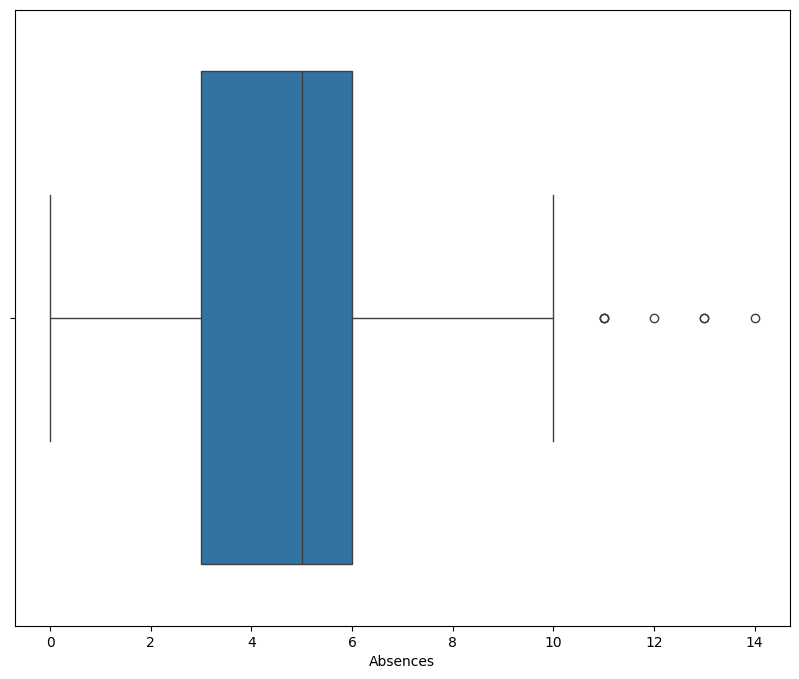

In [163]:
plt.figure(figsize=(10,8))
sns.boxplot(df , x='Absences')
plt.show()

In [164]:
df[df['Absences'] >=10]

,Gender,Parental Education Level,Lunch Type,Test Preparation Course,Study Time,Absences,Math Score,Reading Score,Writing Score,Exam Score
46,Female,High School,Free/Reduced,Completed,12.7,10,52.5,67.5,61.4,181.4
80,Male,College,Standard,Completed,14.4,10,78.1,67.4,71.6,217.1
163,Female,High School,Standard,Uncompleted,10.8,11,58.1,56.4,41.9,156.4
371,Female,High School,Standard,Uncompleted,14.5,10,68.0,62.4,65.4,195.8
615,Male,College,Standard,Uncompleted,7.1,12,45.3,56.3,47.8,149.4
644,Female,High School,Standard,Completed,12.0,10,62.5,63.1,62.8,188.4
670,Male,Bachelor,Standard,Uncompleted,11.6,10,54.1,73.1,66.0,193.2
705,Male,Bachelor,Free/Reduced,Uncompleted,10.4,14,58.4,54.3,56.4,169.1
739,Female,High School,Standard,Uncompleted,8.1,11,49.0,47.5,50.2,146.7
767,Female,College,Free/Reduced,Uncompleted,6.8,10,57.0,61.9,48.0,166.9


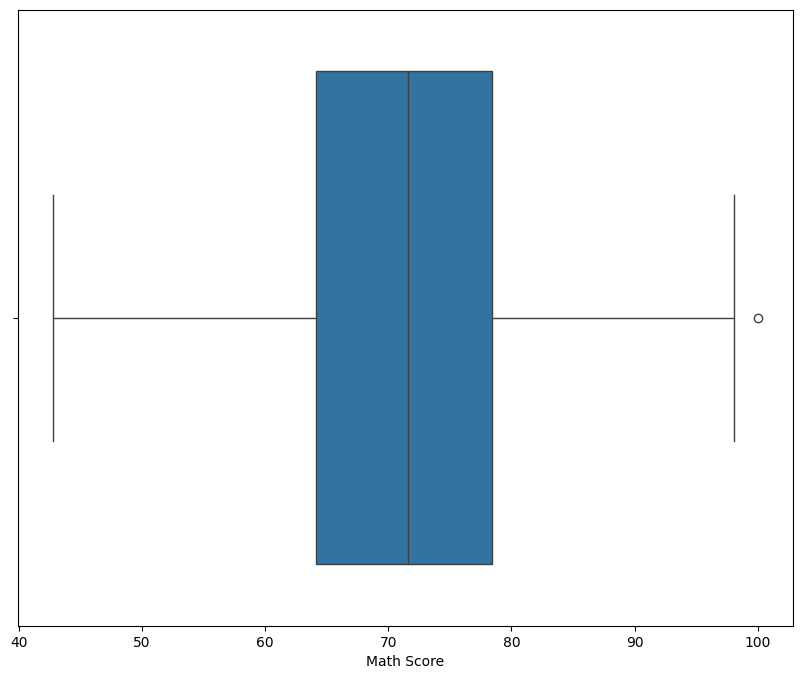

In [165]:
plt.figure(figsize=(10,8))
sns.boxplot(df , x='Math Score')
plt.show()

In [166]:
df[df['Math Score'] >=100]

,Gender,Parental Education Level,Lunch Type,Test Preparation Course,Study Time,Absences,Math Score,Reading Score,Writing Score,Exam Score
561,Male,Master,Standard,Completed,10.8,2,100.0,87.2,84.8,272.0


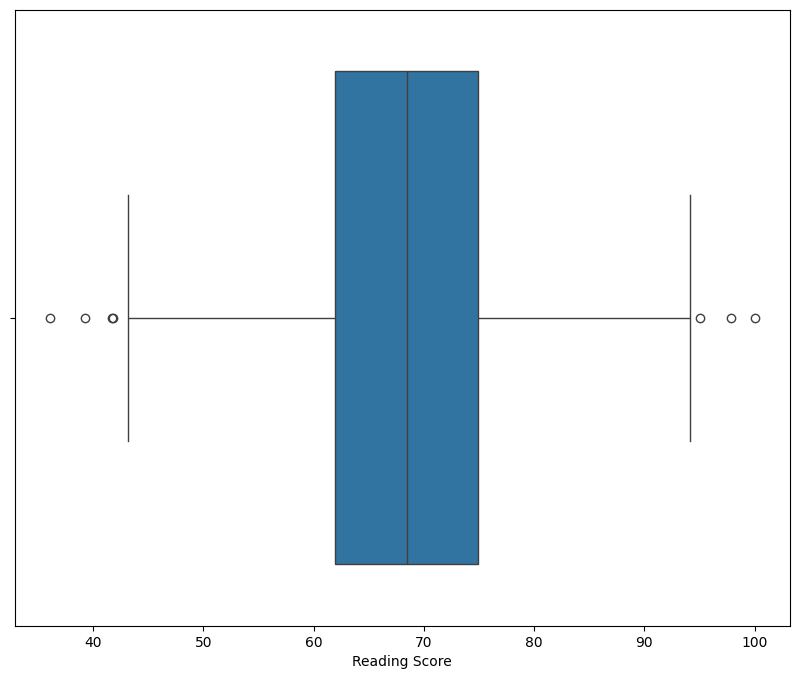

In [167]:
plt.figure(figsize=(10,8))
sns.boxplot(df , x='Reading Score')
plt.show()

In [168]:
df[df['Reading Score'] <40]

,Gender,Parental Education Level,Lunch Type,Test Preparation Course,Study Time,Absences,Math Score,Reading Score,Writing Score,Exam Score
187,Male,High School,Standard,Completed,5.1,8,56.1,36.1,51.1,143.3
984,Female,College,Standard,Uncompleted,3.5,11,43.6,39.3,42.4,125.3


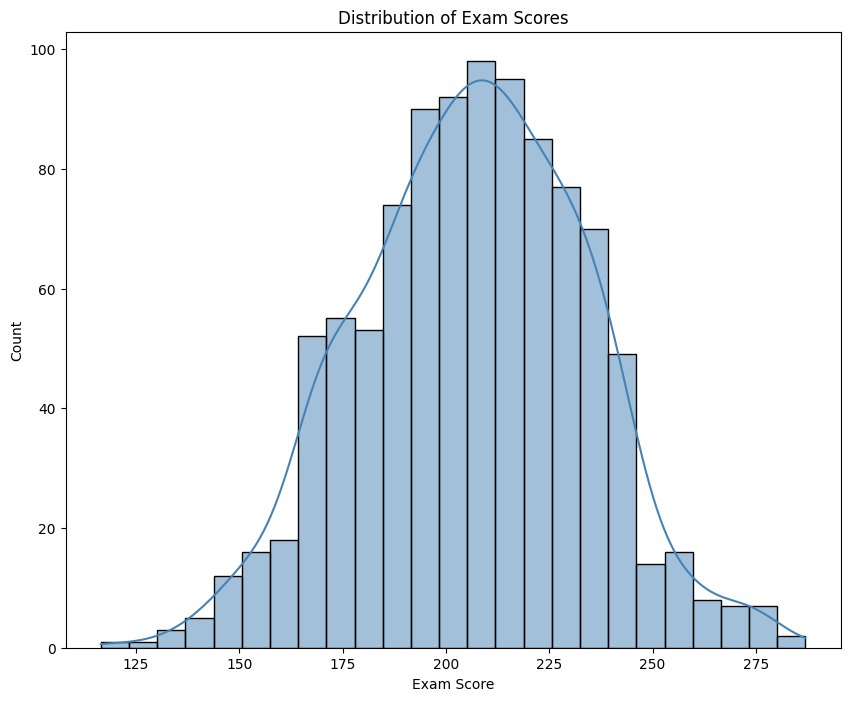

In [169]:
plt.figure(figsize=(10,8))
sns.histplot(df["Exam Score"], bins=25, kde=True, color="steelblue")
plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
plt.show()

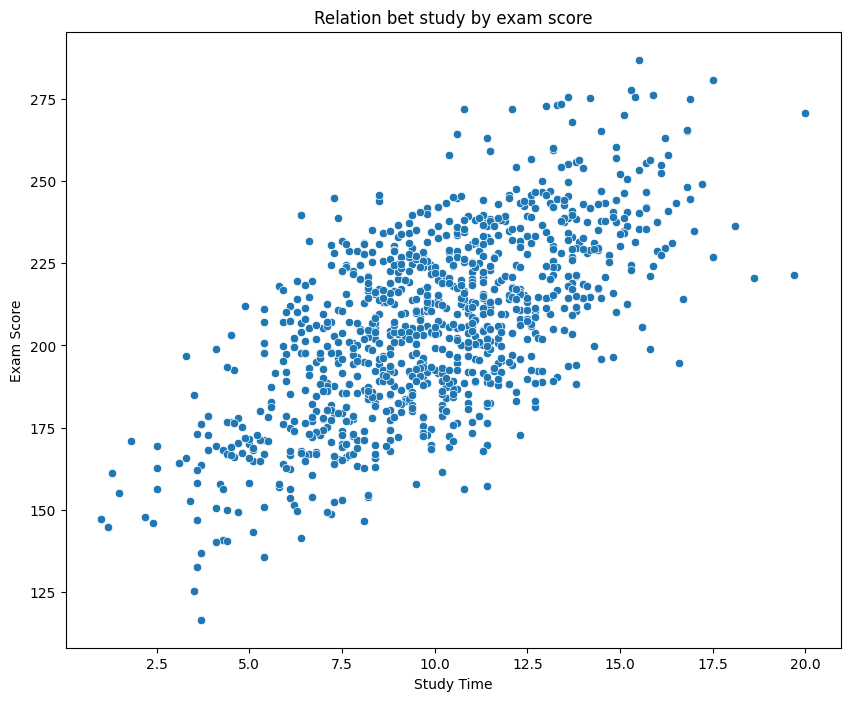

In [170]:
plt.figure(figsize=(10,8))
sns.scatterplot(df , x="Study Time", y="Exam Score")
plt.title("Relation bet study by exam score")
plt.show()

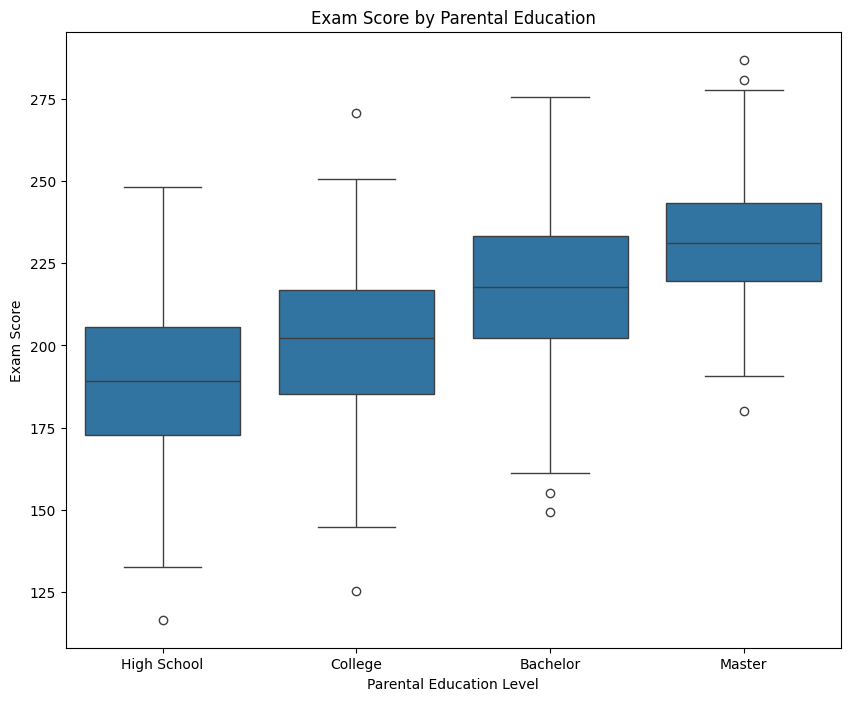

In [171]:
order = ["High School", "College", "Bachelor", "Master"]
df.groupby("Parental Education Level")["Exam Score"].mean().reindex(order).round(1)

plt.figure(figsize=(10,8))
sns.boxplot(data=df, x="Parental Education Level", y="Exam Score", order=order)
plt.title("Exam Score by Parental Education")
plt.show()

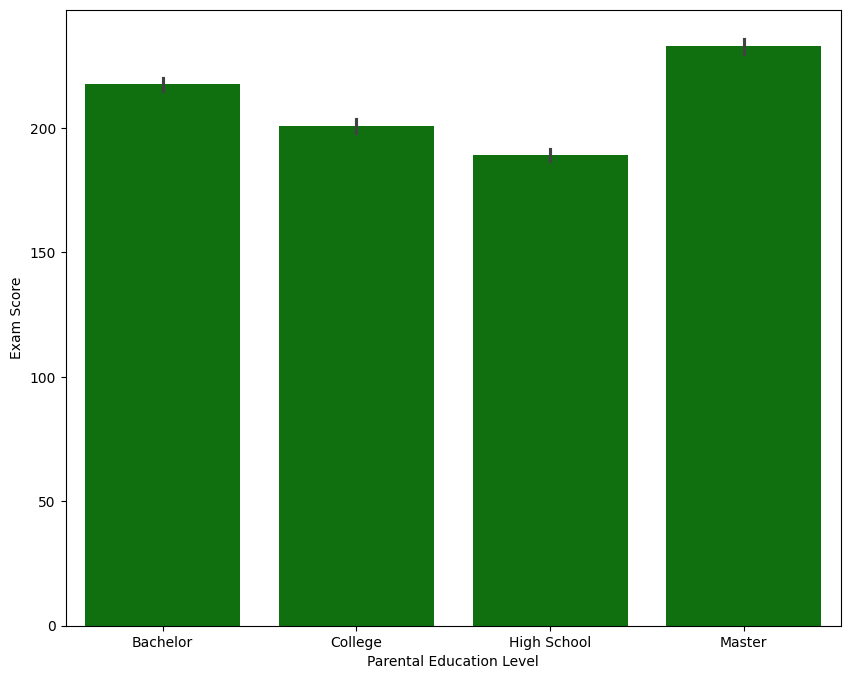

In [172]:
plt.figure(figsize=(10,8))
sns.barplot(df , x='Parental Education Level' , y='Exam Score' , color='green')
plt.show()

In [173]:
plt.figure(figsize=(10,8))
fig = px.pie(df, names='Parental Education Level', values='Exam Score', title='Parental Education by Math Score')
fig.show()

<Figure size 1000x800 with 0 Axes>

#**Encoding**

In [174]:
df["Gender"] = df["Gender"].map({"Male": 0, "Female": 1})
df["Lunch Type"] = df["Lunch Type"].map({"Free/Reduced": 0, "Standard": 1})
df["Test Preparation Course"] = df["Test Preparation Course"].map({"Uncompleted": 0, "Completed": 1})
df["Parental Education Level"] = df["Parental Education Level"].map(
    {"High School": 0, "College": 1, "Bachelor": 2, "Master": 3})

In [175]:
df

,Gender,Parental Education Level,Lunch Type,Test Preparation Course,Study Time,Absences,Math Score,Reading Score,Writing Score,Exam Score
0,0,2,1,0,12.7,6,74.2,68.7,67.7,210.6
1,1,1,1,0,8.1,1,78.0,72.5,62.4,212.9
2,0,1,1,0,10.8,5,67.0,72.0,72.9,211.9
3,0,2,1,0,12.5,3,71.2,76.8,79.8,227.8
4,0,2,1,1,9.9,4,82.9,75.9,75.7,234.5
...,...,...,...,...,...,...,...,...,...,...
995,0,2,1,1,16.1,4,89.1,79.1,84.3,252.5
996,0,2,1,0,10.8,1,80.2,82.4,75.6,238.2
997,1,1,0,0,9.9,4,68.1,74.3,68.1,210.5
998,1,1,0,1,11.0,2,77.7,69.5,71.3,218.5


# **Spliting**

In [176]:
x = df.drop(["Exam Score", "Math Score", "Reading Score", "Writing Score"], axis=1)
y = df["Exam Score"]

In [177]:
x_train , x_test, y_train , y_test = train_test_split(x, y , test_size=0.2 , random_state=42 , shuffle=True)

In [178]:
cols = ["Study Time", "Absences"]
scaler = StandardScaler()

x_train[cols] = scaler.fit_transform(x_train[cols])
x_test[cols]  = scaler.transform(x_test[cols])

# **Build Modeling**

# **RandonForset**

In [179]:
rf_model = RandomForestRegressor(random_state=42)
rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [5, 8, 10],
    'min_samples_leaf': [3, 5, 10],
    'max_features': [0.5, 0.7, 1.0]
}

In [180]:
grid_rf = GridSearchCV(rf_model, rf_params,cv=5, scoring='r2', n_jobs=-1)
grid_rf.fit(x_train, y_train)

print("Best parameters:", grid_rf.best_params_)
print("Best R2 Score:", grid_rf.best_score_)

Best parameters: {'max_depth': 10, 'max_features': 0.7, 'min_samples_leaf': 3, 'n_estimators': 200}
Best R2 Score: 0.8638629451127009


In [181]:
model_Ran = grid_rf.best_estimator_
y_pred = model_Ran.predict(x_test)

In [182]:
print(mean_absolute_error(y_test, y_pred))

8.212145295455677


In [183]:
print(mean_squared_error(y_test, y_pred))

102.85945309472773


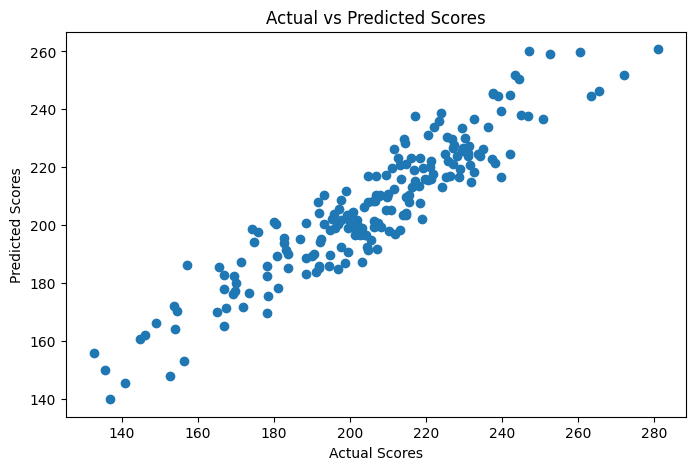

In [184]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Scores")
plt.ylabel("Predicted Scores")
plt.title("Actual vs Predicted Scores")

plt.show()

#**Linear Reg**

In [185]:
lr_model = LinearRegression()

lr_params = {'fit_intercept': [True, False]}

grid_lr = GridSearchCV(lr_model,lr_params,cv=5,scoring='r2')
grid_lr.fit(x_train, y_train)

print("Best parameters:", grid_lr.best_params_)
print("Best R2 Score:", grid_lr.best_score_)

Best parameters: {'fit_intercept': True}
Best R2 Score: 0.9072450210983337


In [186]:
model_Lin = grid_lr.best_estimator_
y_pred = model_Lin.predict(x_test)

In [187]:
print(mean_absolute_error(y_test, y_pred))

7.3619426333437445


In [188]:
print(mean_squared_error(y_test, y_pred))

85.94006202580114


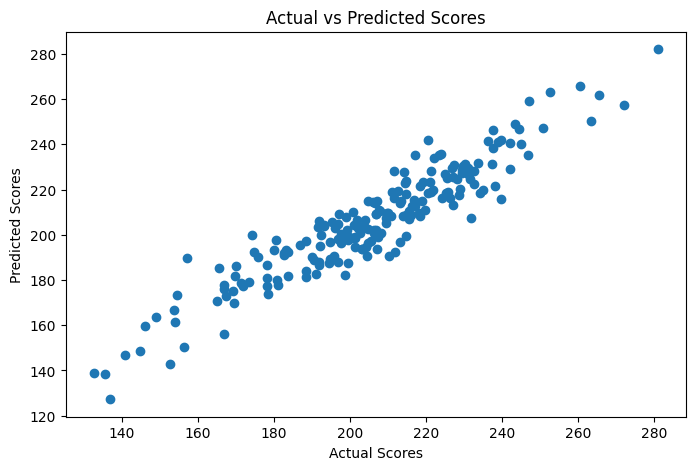

In [189]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Scores")
plt.ylabel("Predicted Scores")
plt.title("Actual vs Predicted Scores")

plt.show()

#**DecisionTree Reg**

In [190]:
dt_model = DecisionTreeRegressor(random_state=42)

dt_params = {
    'max_depth': [3, 5, 8, 10],
    'min_samples_split': [10, 20, 40],
    'min_samples_leaf': [5, 10, 20]
}

In [191]:
grid_dt = GridSearchCV(dt_model,dt_params,cv=5,scoring='r2')
grid_dt.fit(x_train, y_train)

print("Best parameters:", grid_dt.best_params_)
print("Best R2 Score:", grid_dt.best_score_)

Best parameters: {'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 10}
Best R2 Score: 0.7974593151662055


In [192]:
model_Dec = grid_dt.best_estimator_
y_pred = model_Dec.predict(x_test)

In [193]:
print(mean_absolute_error(y_test, y_pred))

9.954674206349207


In [194]:
print(mean_squared_error(y_test, y_pred))

155.64766441258817


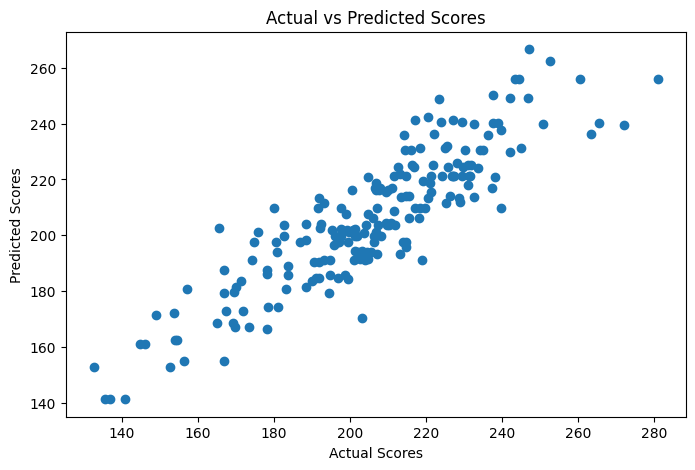

In [195]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Scores")
plt.ylabel("Predicted Scores")
plt.title("Actual vs Predicted Scores")

plt.show()

#**Model Comparison**

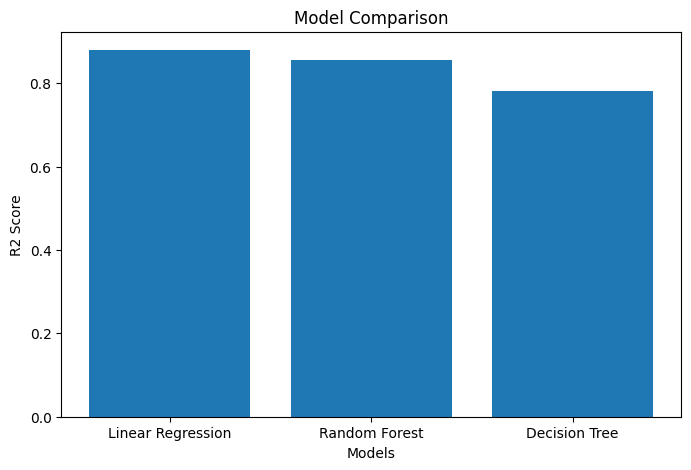

In [196]:
models = {
    "Linear Regression": grid_lr.best_estimator_,
    "Random Forest": grid_rf.best_estimator_,
    "Decision Tree": grid_dt.best_estimator_
}

scores = {}

lr_score = grid_lr.best_estimator_.score(x_test, y_test)
rf_score = grid_rf.best_estimator_.score(x_test, y_test)
dt_score = grid_dt.best_estimator_.score(x_test, y_test)

plt.figure(figsize=(8, 5))
plt.bar(["Linear Regression", "Random Forest", "Decision Tree"], [lr_score, rf_score, dt_score])

plt.title("Model Comparison")
plt.xlabel("Models")
plt.ylabel("R2 Score")
plt.show()

#**Save Scaler**

In [197]:
import joblib

joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

In [198]:
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

#**Save Model**

In [199]:
import joblib

if lr_score >= rf_score and lr_score >= dt_score:
    best_model = grid_lr.best_estimator_
    best_name = "Linear Regression"

elif rf_score >= lr_score and rf_score >= dt_score:
    best_model = grid_rf.best_estimator_
    best_name = "Random Forest"

else:
    best_model = grid_dt.best_estimator_
    best_name = "Decision Tree"

joblib.dump(best_model, "best_model.pkl")

print("Best Model:", best_name)
print("Model Saved Successfully!")

Best Model: Linear Regression
Model Saved Successfully!


#**Feature Importtant**

In [200]:
result = permutation_importance(best_model, x_test, y_test, n_repeats=10, random_state=42, scoring="r2")
importance = pd.Series(result.importances_mean, index=x_test.columns)
importance = importance.sort_values(ascending=False)
print(importance)

Study Time                  0.942329
Parental Education Level    0.772811
Absences                    0.202903
Test Preparation Course     0.050646
Lunch Type                  0.001959
Gender                     -0.000695
dtype: float64


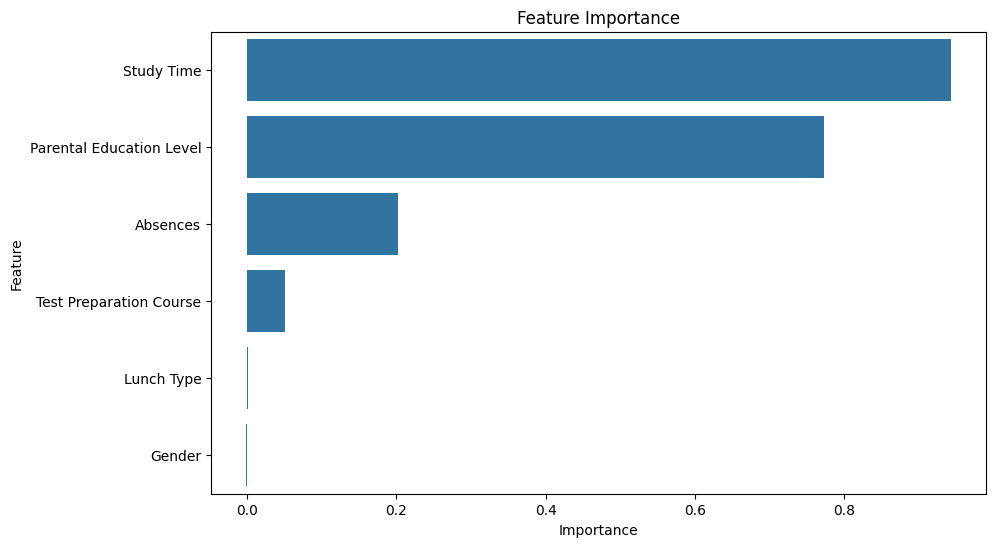

In [201]:
df = importance.reset_index()
df.columns = ['Feature', 'Importance']

plt.figure(figsize=(10, 6))

sns.barplot(df, x='Importance', y='Feature')

plt.title("Feature Importance")
plt.show()